# OCR DETECTION (NUXIA PROJECT):

## 1. Import libraries and dependancies

In [ ]:
#pip install paddleocr
#pip install paddlepaddle
#pip install pytesseract # OTRO OCR

In [22]:
from paddleocr import PaddleOCR
import matplotlib.pyplot as plt
from pathlib import Path
import cv2
import numpy as np
import shutil
#import pytesseract
import json
import re
from datetime import datetime
from datetime import date
from difflib import SequenceMatcher



### Data Structure:

/main 


//pruebas,//pruebas,//pruebas

//data_train (entrenar el classifier)
//data_all (divididas en troqueladas y no con sus previos análisis)

## 2. Classification model for die cut images

### 2.1. Pipeline to obtain the data to train the classifier

In [ ]:
# DO NOT RUN

path = #

In [ ]:
# DO NOT RUN

CARPETA_ORIGEN = path / "pruebas14082026"
CARPETA_DESTINO = path / "data_train"
EXTENSIONES = {".png", ".jpg", ".jpeg"}

CARPETA_DESTINO.mkdir(exist_ok=True)

copiadas = 0
sin_original = []

for subcarpeta in sorted(p for p in CARPETA_ORIGEN.iterdir() if p.is_dir()):
    candidatas = [
        f for f in subcarpeta.iterdir()
        if f.stem.lower() == "original" and f.suffix.lower() in EXTENSIONES
    ]

    if not candidatas:
        sin_original.append(subcarpeta.name)
        continue

    origen = candidatas[0]
    destino_dir = CARPETA_DESTINO / subcarpeta.name
    destino_dir.mkdir(exist_ok=True)

    # copia la imagen (el original queda intacto)
    shutil.copy2(origen, destino_dir / f"original{origen.suffix.lower()}")

    # crea el txt vacío para etiquetar, sin pisar uno que ya hayas rellenado
    etiqueta = destino_dir / "etiqueta.txt"
    if not etiqueta.exists():
        etiqueta.touch()

    copiadas += 1


### 2.2 Train the classifier

In [ ]:
#

### Once we have the final images let's work with them

## 3. Image Preprocessing

In [23]:
paddle_ocr = PaddleOCR(
    lang="es",
    use_angle_cls=True,
    enable_mkldnn=False,                          # idioma (o "en", "ch", etc.)
    use_doc_orientation_classify=False, # desactiva módulos extra para ir más rápido
    use_doc_unwarping=False
)

[2026/10/29 17:10:26] ppocr DEBUG: Namespace(help='==SUPPRESS==', use_gpu=False, use_xpu=False, use_npu=False, use_mlu=False, use_gcu=False, ir_optim=True, use_tensorrt=False, min_subgraph_size=15, precision='fp32', gpu_mem=500, gpu_id=0, image_dir=None, page_num=0, det_algorithm='DB', det_model_dir='C:\\Users\\natal/.paddleocr/whl\\det\\en\\en_PP-OCRv3_det_infer', det_limit_side_len=960, det_limit_type='max', det_box_type='quad', det_db_thresh=0.3, det_db_box_thresh=0.6, det_db_unclip_ratio=1.5, max_batch_size=10, use_dilation=False, det_db_score_mode='fast', det_east_score_thresh=0.8, det_east_cover_thresh=0.1, det_east_nms_thresh=0.2, det_sast_score_thresh=0.5, det_sast_nms_thresh=0.2, det_pse_thresh=0, det_pse_box_thresh=0.85, det_pse_min_area=16, det_pse_scale=1, scales=[8, 16, 32], alpha=1.0, beta=1.0, fourier_degree=5, rec_algorithm='SVTR_LCNet', rec_model_dir='C:\\Users\\natal/.paddleocr/whl\\rec\\latin\\latin_PP-OCRv3_rec_infer', rec_image_inverse=True, rec_image_shape='3, 48,

In [ ]:
# Imágenes para utilizar (Copiar y pegar) en path_img = Path("pruebas14082026/1b4df212")

# 1a0b72b0 (Diferente formato) - Tiene que extraer todo
# 1a3b95bb (Troquelada) - No se extrae nada
# 1aaa2407 (Diferente formato) - Tiene que extraer todo
# 1b4df212 (Diferente formato) - Tiene que extraer todo
# 2b733ecd (Diferente formato) - Tiene que extraer todo
# 2c9787d9 (Diferente formato) - Tiene que extraer todo
# 4d95d836 (Diferente formato) - Tiene que extraer todo

In [ ]:
# Problemas:

# 1a0b72b0 - Junta dos líneas de texto
# 1a3b95bb
# 1aaa2407 - Lote: en Lote1 y vcto: en uct01
# Los dos puntos los convierte en un 1
# 1b4df212 - Está rotada y no entiende bien el número de lote
# 2b733ecd - Junta dos líneas de texto
# 2c9787d9 - "Lote N° :"
# 4d95d836 - LOTE:, y FP Y FE

# ¿Cómo lidiar con rotadas? use_angle_cls=True
# Junta dos cadenas de texto (arriba y abajo en una)
# Convierte dos puntos en "1"

In [40]:
path_img = Path("pruebas14082026/2c9787d9") #Cambiar si trabajamos con otra carpeta

In [30]:
img = cv2.imread(str(path_img / "original.png"))

In [31]:
resultado = paddle_ocr.predict(img)

for res in resultado:
    #res.print()                      # muestra todo en consola
    res.save_to_img(str(path_img / "ocr_no_pre.png"))        # imagen con las cajas dibujadas
    res.save_to_json(str(path_img / "report.json"))     # JSON con textos y coordenadas

Extraer el texto

In [50]:
ruta_json = path_img / "report.json"

with open(ruta_json, "r", encoding="utf-8") as f:
    report = json.load(f)

rec_texts = report["rec_texts"]

# No modificar ni normalizar el texto original
texto = [str(text) for text in rec_texts]

# Unir los textos para buscar etiquetas o fechas
texto = "\n".join(texto)

print(texto)

Lote N° : FD250359
Fecha de Fab.: 01/2025
Fecha de Exp.: 12/2026


Función Maestra:

In [41]:
def funcion_maestra(texto):

    resultado = {
        "lote": None,
        "fecha_fabricacion": None,
        "fecha_caducidad": None
    }

    # ------------------------------------------------------------------
    # Configuración: para otros idiomas o medicamentos, amplía estos conjuntos
    # (en mayúsculas, sin espacios ni símbolos, y con O en lugar de 0)
    # ------------------------------------------------------------------
    ETIQ_LOTE = ["LOT", "LOTE", "BATCH", "LOTNO", "LOTNR"]
    ETIQ_FAB = ["MANUF", "MANUFACTURED", "MFG", "MFD", "MAN", "FAB", "FABRICACION", "PROD"]
    ETIQ_CAD = ["EXP", "EXF", "EXPIRY", "EXPIRES", "CAD", "CADUCIDAD", "USEBY"]

    patron_valor = re.compile(r"[A-Z0-9][A-Z0-9./_-]*", re.IGNORECASE)
    patron_pegado = re.compile(r"^(?:LOTE|LOT|BATCH)[.\-/]?([A-Z0-9][A-Z0-9./_-]*)$", re.IGNORECASE)

    patron_fecha = re.compile(
        r"(?<![\d/.\-])(?:"
        r"(?P<y5>\d{4})[/.\-](?P<m5>\d{1,2})[/.\-](?P<d5>\d{1,2})"         # aaaa/mm/dd
        r"|(?P<d>\d{1,2})[/.\-](?P<m1>\d{1,2})[/.\-](?P<y1>\d{4}|\d{2})"   # dd/mm/aaaa o dd/mm/aa
        r"|(?P<y2>\d{4})[/.\-](?P<m2>\d{1,2})"                              # aaaa-mm
        r"|(?P<m3>\d{1,2})[/.\-](?P<y3>\d{4})"                              # mm/aaaa
        r"|(?<![A-Za-z])(?P<m6>\d{1,2})/(?P<y6>\d{2})"                      # mm/aa (solo con "/")
        r"|(?P<m4>\d{1,2}) (?P<y4>\d{4})"                                   # mm aaaa
        r")(?![\d/.\-])"
    )

    # ------------------------------------------------------------------
    # 1. LOTE
    # ------------------------------------------------------------------
    lineas = [l.strip() for l in texto.splitlines() if l.strip()]

    # Para cada línea se guarda una lista de tokens con sus características:
    # (texto, es_etiqueta_lote, es_valor_lote, valor_pegado_a_etiqueta)
    info_lineas = []
    for linea in lineas:
        partes = re.split(r"[\s:：#=;,]+", linea)
        toks = [p.strip(" .°º") for p in partes if p.strip(" .°º")]

        info = []
        for t in toks:
            # ¿Es una etiqueta de lote (aproximada)?
            norm_t = re.sub(r"[^A-Z0-9]", "", t.upper()).replace("0", "O")
            sim_t = 0.0
            if norm_t:
                sim_t = max(SequenceMatcher(None, norm_t, e).ratio() for e in ETIQ_LOTE)
            es_etiqueta = sim_t >= 0.8

            # ¿Es un valor de lote válido? Se evalúa el token y, si la etiqueta
            # viene pegada al valor (LOT123), también el valor pegado.
            m_pegado = patron_pegado.match(t)
            pegado = m_pegado.group(1) if m_pegado else None

            flags = []
            for c in (t, pegado):
                if c is None:
                    flags.append(False)
                    continue
                norm_c = re.sub(r"[^A-Z0-9]", "", c.upper()).replace("0", "O")
                sim_c = 0.0
                if norm_c:
                    sim_c = max(SequenceMatcher(None, norm_c, e).ratio() for e in ETIQ_LOTE)
                flags.append(
                    patron_valor.fullmatch(c) is not None
                    and len(c) >= 3
                    and any(ch.isdigit() for ch in c)
                    and patron_fecha.fullmatch(c) is None
                    and sim_c < 0.8
                )
            es_valor, pegado_valido = flags

            info.append((t, es_etiqueta, es_valor, pegado if pegado_valido else None))
        info_lineas.append(info)

    lote = None
    for i, info in enumerate(info_lineas):
        for k, (t, es_etiqueta, es_valor, pegado) in enumerate(info):
            # Etiqueta pegada al valor: LOT123, LOTE-ABC12, BATCH.5567
            if pegado:
                lote = pegado
                break

            if not es_etiqueta:
                continue

            # Candidatos por orden de prioridad:
            # a) mismo renglón: después de la etiqueta y luego antes
            # b) líneas siguientes (hasta 3)
            # c) líneas anteriores (hasta 2), valor impreso antes de la etiqueta
            candidatos = [x[0] for x in info[k + 1:] if x[2]]
            candidatos += [x[0] for x in info[:k][::-1] if x[2]]
            for j in range(i + 1, min(i + 4, len(info_lineas))):
                candidatos += [x[0] for x in info_lineas[j] if x[2]]
            for j in range(i - 1, max(i - 3, -1), -1):
                candidatos += [x[0] for x in info_lineas[j] if x[2]]

            if candidatos:
                lote = candidatos[0]
                break

            # Plan B: no hay etiqueta, se busca un código que parezca un lote
    if lote is None:
        patron_unidad = re.compile(
            r"^\d+([.,]\d+)?(MG|ML|G|MCG|UG|UI|IU|KG|L|MM|CM)$", re.IGNORECASE
        )
        for info in info_lineas:
            for t, es_etiqueta, es_valor, pegado in info:
                if (
                    es_valor                                  # alfanumérico, con dígito, no es fecha ni etiqueta
                    and len(t) >= 4
                    and any(c.isalpha() for c in t)           # mezcla letras y números
                    and not patron_unidad.match(t)            # descarta dosis: 500MG, 10ML...
                ):
                    lote = t
                    break
            if lote:
                break

    resultado["lote"] = lote

    # ------------------------------------------------------------------
    # 2. FECHAS
    # ------------------------------------------------------------------
    fechas = []  # (año, mes, inicio, fin)
    for m in patron_fecha.finditer(texto):
        g = m.groupdict()
        if g["y5"]:
            mes, anio = int(g["m5"]), g["y5"]
        elif g["d"]:
            mes, anio = int(g["m1"]), g["y1"]
        elif g["y2"]:
            mes, anio = int(g["m2"]), g["y2"]
        elif g["m3"]:
            mes, anio = int(g["m3"]), g["y3"]
        elif g["m6"]:
            mes, anio = int(g["m6"]), g["y6"]
        else:
            mes, anio = int(g["m4"]), g["y4"]

        anio = int(anio) + (2000 if len(anio) == 2 else 0)
        if 1 <= mes <= 12 and 2000 <= anio <= 2100:
            fechas.append((anio, mes, m.start(), m.end()))

    unicas = sorted({(a, mes) for a, mes, _, _ in fechas})
    fab = cad = None

    if len(unicas) >= 2:
        # El orden cronológico no depende de lo bien que el OCR lea las etiquetas
        fab, cad = unicas[0], unicas[-1]

    elif len(unicas) == 1:
        a, mes, ini, fin = fechas[0]
        tipo = None

        # Palabras cercanas: primero las anteriores a la fecha, luego las posteriores
        antes = re.findall(r"[A-Za-z0-9]+", texto[max(0, ini - 25):ini])[-2:]
        despues = re.findall(r"[A-Za-z0-9]+", texto[fin:fin + 25])[:2]
        for palabra in list(reversed(antes)) + despues:
            if palabra.isdigit():
                continue
            norm_p = re.sub(r"[^A-Z0-9]", "", palabra.upper()).replace("0", "O")
            if not norm_p:
                continue
            sc_cad = max(SequenceMatcher(None, norm_p, e).ratio() for e in ETIQ_CAD)
            sc_fab = max(SequenceMatcher(None, norm_p, e).ratio() for e in ETIQ_FAB)
            if max(sc_cad, sc_fab) >= 0.5:
                tipo = "cad" if sc_cad >= sc_fab else "fab"
                break

        # Sin etiqueta fiable: si es futura se asume caducidad, si no, fabricación
        if tipo is None:
            hoy = date.today()
            tipo = "cad" if (a, mes) >= (hoy.year, hoy.month) else "fab"

        if tipo == "cad":
            cad = (a, mes)
        else:
            fab = (a, mes)

    resultado["fecha_fabricacion"] = f"{fab[0]}-{fab[1]:02d}" if fab else None
    resultado["fecha_caducidad"] = f"{cad[0]}-{cad[1]:02d}" if cad else None

    return resultado


Ejemplo:

In [54]:
# Ejemplo de uso
datos = funcion_maestra(texto)

print(json.dumps(datos, indent=4, ensure_ascii=False))

{
    "texto_original": "Lote N° : FD250359\nFecha de Fab.: 01/2025\nFecha de Exp.: 12/2026",
    "lote": "FD250359",
    "fecha_produccion": "01/2025",
    "fecha_caducidad": "12/2026"
}


### Vamos a probar con una selección de 15 imágenes, para ello definimos una función

In [44]:
def extraer_texto_paddle(ocr, imagen):
    textos = []
    predecir = getattr(ocr, "predict", None)

    if callable(predecir):
        predicciones = predecir(imagen)
        for pagina in predicciones:
            datos = pagina.json if hasattr(pagina, "json") else pagina
            if callable(datos):
                datos = datos()
            if isinstance(datos, str):
                datos = json.loads(datos)
            if isinstance(datos, dict):
                datos = datos.get("res", datos)
                if isinstance(datos, dict):
                    textos.extend(str(texto) for texto in datos.get("rec_texts", []))
    else:
        predicciones = ocr.ocr(imagen, cls=True)
        for pagina in predicciones:
            if not pagina:
                continue
            for linea in pagina:
                if len(linea) > 1 and isinstance(linea[1], (tuple, list)):
                    textos.append(str(linea[1][0]))

    return textos


def process_image(ocr, img):
    rec_texts = extraer_texto_paddle(ocr, img)
    ruta_json = path_img / "report.json"

    with open(ruta_json, "w", encoding="utf-8") as f:
        json.dump({"rec_texts": rec_texts}, f, ensure_ascii=False, indent=2)

    texto = "\n".join(rec_texts)
    print("Texto OCR:")
    print(texto)
    return funcion_maestra(texto)

In [ ]:
# Copiar y pegar para más comodidad

# 1- carpeta1-0508_0d5e6be4_original.png
# 2- carpeta1-0508_09d0cb17_original.png
# 3- carpeta1-0508_036f0258_original.png
# 4- carpeta1-0508_0421afbc_original.png
# 5- carpeta1-0508_0724983f_original.png
# 6- carpeta2-1408_03d36f66_original.png
# 7- carpeta2-1408_0303fac1_original.png
# 8- carpeta2-1408_0656b9aa_original.png
# 9- carpeta2-1408_01200be4_original.png
# 10- carpeta2-1408_011935a0_original.png
# 11- carpeta3-1609_09a9ac3d_original.png
# 12- carpeta3-1609_089af73d_original.png
# 13- carpeta3-1609_0546ea28_original.png
# 14- carpeta3-1609_0670c123_original.png
# 15- carpeta3-1609_0914ed75_original.png

In [147]:
path_img = Path("muestra_15_imagenes")
img = cv2.imread(str(path_img / "carpeta2-1408_0656b9aa_original.png"))

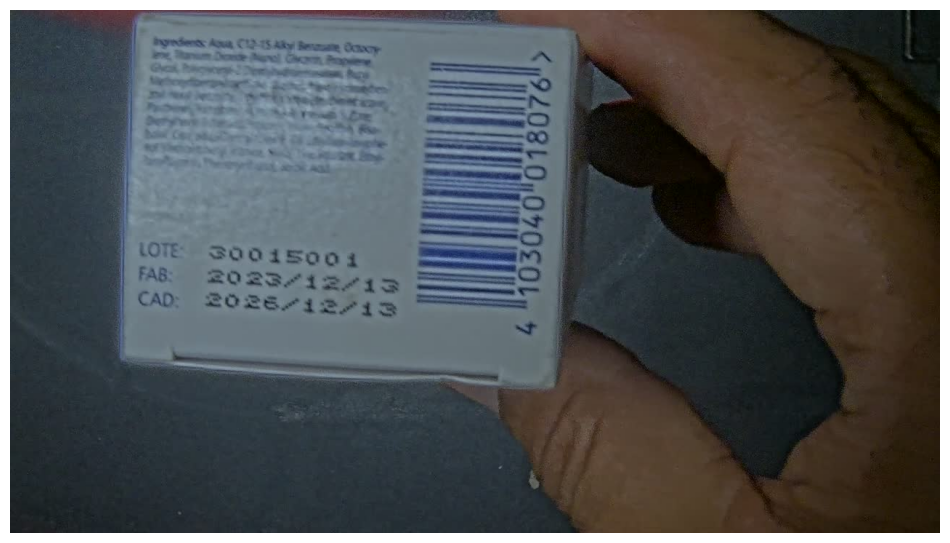

In [148]:
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 8))
plt.imshow(img_rgb)
plt.axis("off")
plt.show()

In [149]:
process_image(paddle_ocr, img)

Texto OCR:
Inpredents Aoua, C12-15 Aky Benzate Öctity
1076
LOTE: 30015001
FAB:
2023/12/13
CAD:
2026/12/13


{'lote': '30015001',
 'fecha_fabricacion': '2023-12',
 'fecha_caducidad': '2026-12'}

In [ ]:
# Detecta todas la información de las imágenes:

# 1- Sí
# 2- No
# 3- Sí
# 4- Sí
# 5- Sí (Confunde D con 0)
# 6- Sí
# 7- Sí
# 8- Sí
# 9- 
# 10- 
# 11- 
# 12- 
# 13- 
# 14- 
# 15- 

### Let's try with different filters

In [ ]:
# GRIS

gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
imagen_limpia = clahe.apply(gris)
cv2.imwrite("salida/gris.png", imagen_limpia)

imagen_3c = cv2.cvtColor(imagen_limpia, cv2.COLOR_GRAY2BGR) # Necesitas tres canales ya que Paddle OCR lo requiere

for res in paddle_ocr.predict(imagen_3c):
    res.print()
    res.save_to_img("salida")        # imagen con las cajas dibujadas
    res.save_to_json("salida") 

True

In [ ]:
# CLAHE

lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
l, a, b = cv2.split(lab)
l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)

imagen_3c = cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2BGR)

cv2.imwrite("salida/clahe.png", imagen_3c)

for res in paddle_ocr.predict(imagen_3c):
    res.print()
    res.save_to_img("salida")        
    res.save_to_json("salida") 

In [ ]:
# ADAPTATIVE

gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
bw = cv2.adaptiveThreshold(gris, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,cv2.THRESH_BINARY, 31, 15)

imagen_3c = cv2.cvtColor(bw, cv2.COLOR_GRAY2BGR) 

cv2.imwrite("salida/adaptative.png", imagen_3c)

for res in paddle_ocr.predict(imagen_3c):
    res.print()
    res.save_to_img("salida")        
    res.save_to_json("salida") 


In [ ]:

def brillo_contraste(img, alpha=1.3, beta=20):
    # alpha: contraste (1.0 = igual), beta: brillo (-100..100)
    return cv2.convertScaleAbs(img, alpha=alpha, beta=beta)


def gamma(img, g=0.6):
    # g < 1 aclara, g > 1 oscurece
    tabla = np.array([(i / 255.0) ** g * 255 for i in range(256)]).astype("uint8")
    return cv2.LUT(img, tabla)



def normalizar(img):
    return cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)


### Vamos a probar con otro OCR

In [ ]:
path_img = Path("pruebas14082026/4d95d836")
img = cv2.imread(str(path_img / "original.png"))

In [ ]:
if img is None:
    raise FileNotFoundError(
        f"No se encuentra la imagen: {path_img}"
    )

# Convertir a escala de grises
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Mejorar el contraste mediante binarización
processed = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)[1]

# Ejecutar OCR
config = "--psm 6"
text = pytesseract.image_to_string(
    processed,
    config=config
)

# Mostrar el texto reconocido en el terminal
print("Texto reconocido:")
print(text)

# Mostrar la imagen original y la procesada
cv2.imshow("Imagen original", img)
cv2.imshow("Imagen procesada", processed)

cv2.waitKey(0)
cv2.destroyAllWindows()

## Prueba de filtros Natalia 
Voy a probar el Bilaterla Filter, CLAHE y Black-Hat

In [42]:
import cv2
import numpy as np

def pipeline_reescalado_bilateral(img_bgr):
    """Filtro 1: Reescalado 2x + Filtro Bilateral."""
    h, w = img_bgr.shape[:2]
    if max(h, w) < 1500:
        img_bgr = cv2.resize(img_bgr, (w * 2, h * 2), interpolation=cv2.INTER_CUBIC)
    filtered = cv2.bilateralFilter(img_bgr, d=7, sigmaColor=50, sigmaSpace=50)
    return np.ascontiguousarray(filtered, dtype=np.uint8)

def pipeline_polaridad_clahe(img_bgr):
    """Filtro 2: Corrección de polaridad + CLAHE adaptativo."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    if np.mean(gray) < 127:
        gray = cv2.bitwise_not(gray)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    gray_clahe = clahe.apply(gray)
    return np.ascontiguousarray(cv2.cvtColor(gray_clahe, cv2.COLOR_GRAY2BGR), dtype=np.uint8)

def pipeline_blackhat_corregido(img_bgr):
    """Filtro 3: Operación morfológica Black-Hat (Resta para relieve/sombras)."""
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (9, 9))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    enhanced = cv2.subtract(gray, blackhat)
    return np.ascontiguousarray(cv2.cvtColor(enhanced, cv2.COLOR_GRAY2BGR), dtype=np.uint8)

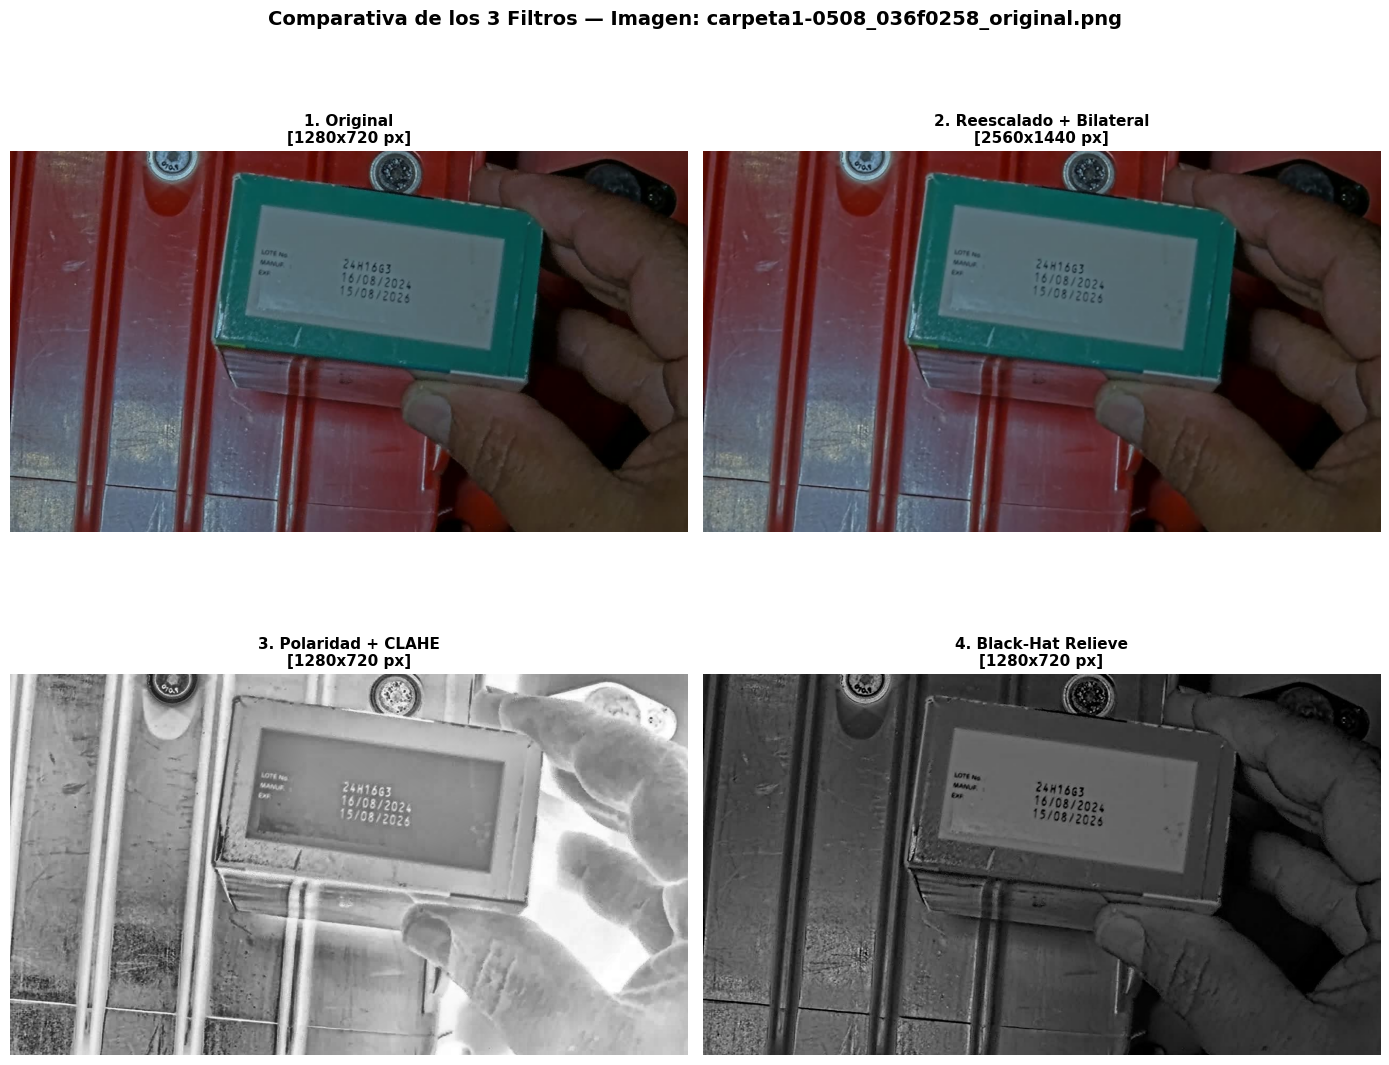

In [27]:
import os
import glob
import pandas as pd
from paddleocr import PaddleOCR
import matplotlib.pyplot as plt

# 1. Obtener la primera imagen de la carpeta muestra
rutas_imagenes = glob.glob(os.path.join("muestra_15_imagenes", "*.png"))
if not rutas_imagenes:
    raise FileNotFoundError("No se encontraron imágenes en 'muestra_15_imagenes'")

ruta_ejemplo = rutas_imagenes[0]
nombre_ejemplo = os.path.basename(ruta_ejemplo)

# 2. Cargar imagen original
img_orig = cv2.imread(ruta_ejemplo)

# 3. Generar los dos outputs de los filtros elegidos
out_filtro_1 = pipeline_reescalado_bilateral(img_orig)
out_filtro_2 = pipeline_polaridad_clahe(img_orig)
out_filtro_3 = pipeline_blackhat_corregido(img_orig)

# 4. Mostrar la imagen original y los 3 filtros en una cuadrícula 2x2
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# Subplot 1: Original
axes[0, 0].imshow(cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB))
h0, w0 = img_orig.shape[:2]
axes[0, 0].set_title(f"1. Original\n[{w0}x{h0} px]", fontsize=11, fontweight='bold')
axes[0, 0].axis('off')

# Subplot 2: Filtro 1 (Reescalado + Bilateral)
axes[0, 1].imshow(cv2.cvtColor(out_filtro_1, cv2.COLOR_BGR2RGB))
h1, w1 = out_filtro_1.shape[:2]
axes[0, 1].set_title(f"2. Reescalado + Bilateral\n[{w1}x{h1} px]", fontsize=11, fontweight='bold')
axes[0, 1].axis('off')

# Subplot 3: Filtro 2 (Polaridad + CLAHE)
axes[1, 0].imshow(cv2.cvtColor(out_filtro_2, cv2.COLOR_BGR2RGB))
h2, w2 = out_filtro_2.shape[:2]
axes[1, 0].set_title(f"3. Polaridad + CLAHE\n[{w2}x{h2} px]", fontsize=11, fontweight='bold')
axes[1, 0].axis('off')

# Subplot 4: Filtro 3 (Black-Hat Relieve)
axes[1, 1].imshow(cv2.cvtColor(out_filtro_3, cv2.COLOR_BGR2RGB))
h3, w3 = out_filtro_3.shape[:2]
axes[1, 1].set_title(f"4. Black-Hat Relieve\n[{w3}x{h3} px]", fontsize=11, fontweight='bold')
axes[1, 1].axis('off')

plt.suptitle(f"Comparativa de los 3 Filtros — Imagen: {nombre_ejemplo}", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [43]:
rutas_imagenes = glob.glob(os.path.join("muestra_15_imagenes", "*.png"))
if not rutas_imagenes:
    raise FileNotFoundError("No se encontraron imágenes en 'muestra_15_imagenes'")
    filtros_natalia = {
    "reescalado_bilateral": pipeline_reescalado_bilateral,
    "polaridad_clahe": pipeline_polaridad_clahe,
    "blackhat_corregido": pipeline_blackhat_corregido,
}

for img in rutas_imagenes:
    for filter in filtros_natalia:
        img_bgr = cv2.imread(img)
        if img_bgr is None:
            print(f"Error al leer la imagen: {img}")
            continue
        processed_img = filtros_natalia[filter](img_bgr)
        output_dir = os.path.join("salida", filter)
        os.makedirs(output_dir, exist_ok=True)
        output_path = os.path.join(output_dir, os.path.basename(img))
        cv2.imwrite(output_path, processed_img)


In [46]:
import os
import glob
import pandas as pd
from pathlib import Path

# 1. Definir los tres directorios de entrada
carpetas_filtros = {
    "blackhat_corregido": os.path.join("salida", "blackhat_corregido"),
    "polaridad_clahe": os.path.join("salida", "polaridad_clahe"),
    "reescalado_bilateral": os.path.join("salida", "reescalado_bilateral")
}

filas_resultados = []

# 2. Iterar sobre cada filtro y procesar sus imágenes
for nombre_filtro, ruta_carpeta in carpetas_filtros.items():
    # Buscar todas las imágenes de la carpeta (.png, .jpg, .jpeg)
    patron = os.path.join(ruta_carpeta, "*.png")
    imagenes = glob.glob(patron)
    
    print(f"Procesando {len(imagenes)} imágenes para el filtro: {nombre_filtro}...")
    
    for ruta_img in sorted(imagenes):
        nombre_archivo = os.path.basename(ruta_img)
        
        # 2.1. Extraer el texto con PaddleOCR usando la función auxiliar
        lineas_texto = extraer_texto_paddle(paddle_ocr, cv2.imread(ruta_img))
        texto_ocr_raw = "\n".join(lineas_texto)
        
        # 2.2. Pasar el texto por la funcion_maestra de tu compañero
        campos_extraidos = funcion_maestra(texto_ocr_raw)
        
        # 2.3. Estructurar la fila del DataFrame
        fila = {
            "nombre_imagen": nombre_archivo,
            "filtro_aplicado": nombre_filtro,
            "ruta_completa": ruta_img,
            "texto_ocr_raw": texto_ocr_raw
        }
        
        # Desempaquetar todos los campos que devuelve funcion_maestra (lote, caducidad, etc.)
        if isinstance(campos_extraidos, dict):
            fila.update(campos_extraidos)
            
        filas_resultados.append(fila)

# 3. Convertir la lista de resultados a DataFrame
df_comparativa = pd.DataFrame(filas_resultados)

# 4. Guardar en CSV para fácil análisis o comparación
df_comparativa.to_csv("salida/comparativa_filtros_completa.csv", index=False, encoding="utf-8-sig")

print("\n✓ Proceso finalizado.")
print(f"Total de registros generados: {len(df_comparativa)} filas.")

# Visualizar las primeras filas en el cuaderno
display(df_comparativa.head(10))

Procesando 15 imágenes para el filtro: blackhat_corregido...
[2026/10/30 10:35:51] ppocr DEBUG: dt_boxes num : 6, elapsed : 0.2140045166015625
[2026/10/30 10:35:51] ppocr DEBUG: cls num  : 6, elapsed : 0.016998767852783203
[2026/10/30 10:35:52] ppocr DEBUG: rec_res num  : 6, elapsed : 0.26853322982788086
[2026/10/30 10:35:52] ppocr DEBUG: dt_boxes num : 7, elapsed : 0.1541128158569336
[2026/10/30 10:35:52] ppocr DEBUG: cls num  : 7, elapsed : 0.11968636512756348
[2026/10/30 10:35:53] ppocr DEBUG: rec_res num  : 7, elapsed : 0.8883557319641113
[2026/10/30 10:35:53] ppocr DEBUG: dt_boxes num : 6, elapsed : 0.11552214622497559
[2026/10/30 10:35:53] ppocr DEBUG: cls num  : 6, elapsed : 0.023521900177001953
[2026/10/30 10:35:54] ppocr DEBUG: rec_res num  : 6, elapsed : 0.8254399299621582
[2026/10/30 10:35:54] ppocr DEBUG: dt_boxes num : 2, elapsed : 0.2347702980041504
[2026/10/30 10:35:54] ppocr DEBUG: cls num  : 2, elapsed : 0.20472192764282227
[2026/10/30 10:35:55] ppocr DEBUG: rec_res nu

,nombre_imagen,filtro_aplicado,ruta_completa,texto_ocr_raw,lote,fecha_fabricacion,fecha_caducidad
0,carpeta1-0508_036f0258_original.png,blackhat_corregido,salida\blackhat_corregido\carpeta1-0508_036f02...,LOTENO\nMAUF.\n24H1663\nEAF\n16/08/2024\n15/08...,24H1663,2024-08,2026-08
1,carpeta1-0508_0421afbc_original.png,blackhat_corregido,salida\blackhat_corregido\carpeta1-0508_0421af...,932155\nLat\n08124\nWad!\n08/26\nExp,None,None,2026-08
2,carpeta1-0508_0724983f_original.png,blackhat_corregido,salida\blackhat_corregido\carpeta1-0508_072498...,40799\nLOt.AFO434A\nF.Manuf.:09/2024\nF.x.1C8/...,AFO434A,2024-09,2026-08
3,carpeta1-0508_09d0cb17_original.png,blackhat_corregido,salida\blackhat_corregido\carpeta1-0508_09d0cb...,2024/11104\n202411042026/11/03,None,None,None
4,carpeta1-0508_0d5e6be4_original.png,blackhat_corregido,salida\blackhat_corregido\carpeta1-0508_0d5e6b...,6TIN18901127028504\nSrNo.88NTAW8628U\nLote No....,No.NF088C,2024-09,None
5,carpeta2-1408_011935a0_original.png,blackhat_corregido,salida\blackhat_corregido\carpeta2-1408_011935...,L2120064\nV:12-2026,L2120064,None,2026-12
6,carpeta2-1408_01200be4_original.png,blackhat_corregido,salida\blackhat_corregido\carpeta2-1408_01200b...,Lote:\nElab:\nCad:\n4031037\n200IC/24\n20/DIC2...,4031037,None,None
7,carpeta2-1408_0303fac1_original.png,blackhat_corregido,salida\blackhat_corregido\carpeta2-1408_0303fa...,HDZAVS\n12-2026,None,None,2026-12
8,carpeta2-1408_03d36f66_original.png,blackhat_corregido,salida\blackhat_corregido\carpeta2-1408_03d36f...,EXP\n122026\nLOT\nTDTX3\nMFD\n012024,TDTX3,None,None
9,carpeta2-1408_0656b9aa_original.png,blackhat_corregido,salida\blackhat_corregido\carpeta2-1408_0656b9...,hyneAaCSAkye\n103040018076\nLOTE-\n30015001\nF...,30015001,None,None


In [40]:
# Procesar cada imagen con los tres filtros y guardar resultados comparables.
from pathlib import Path
import pandas as pd

CARPETA_MUESTRA = Path("muestra_15_imagenes")
ARCHIVO_RESULTADOS = CARPETA_MUESTRA / "resultados_ocr_filtros.csv"
filtros_natalia = {
    "reescalado_bilateral": pipeline_reescalado_bilateral,
    "polaridad_clahe": pipeline_polaridad_clahe,
    "blackhat_corregido": pipeline_blackhat_corregido,
}

rutas_imagenes = sorted(
    ruta for ruta in CARPETA_MUESTRA.iterdir()
    if ruta.is_file() and ruta.suffix.lower() in {".png", ".jpg", ".jpeg"}
)
if len(rutas_imagenes) != 15:
    raise ValueError(
        f"Se esperaban 15 imagenes en {CARPETA_MUESTRA}, "
        f"pero se encontraron {len(rutas_imagenes)}."
    )

filas_resultados = []
for ruta_imagen in rutas_imagenes:
    imagen_original = cv2.imread(str(ruta_imagen))
    if imagen_original is None:
        raise ValueError(f"No se pudo leer la imagen: {ruta_imagen}")

    for nombre_filtro, aplicar_filtro in filtros_natalia.items():
        imagen_filtrada = aplicar_filtro(imagen_original)
        texto_ocr = "\n".join(extraer_texto_paddle(paddle_ocr, imagen_filtrada))
        campos = funcion_maestra(texto_ocr)
        filas_resultados.append({
            "imagen": ruta_imagen.name,
            "filtro": nombre_filtro,
            "texto_ocr": texto_ocr,
            **campos,
        })

resultados_filtros = pd.DataFrame(filas_resultados)
resultados_filtros.to_csv(ARCHIVO_RESULTADOS, index=False, encoding="utf-8-sig")
print(f"Procesadas {len(rutas_imagenes)} imagenes con {len(filtros_natalia)} filtros.")
print(f"Resultados guardados en: {ARCHIVO_RESULTADOS}")
display(resultados_filtros)

[2026/10/29 17:36:32] ppocr DEBUG: dt_boxes num : 6, elapsed : 0.9549932479858398
[2026/10/29 17:36:32] ppocr DEBUG: cls num  : 6, elapsed : 0.1270289421081543
[2026/10/29 17:36:33] ppocr DEBUG: rec_res num  : 6, elapsed : 0.6838037967681885
[2026/10/29 17:36:33] ppocr DEBUG: dt_boxes num : 6, elapsed : 0.1996314525604248
[2026/10/29 17:36:33] ppocr DEBUG: cls num  : 6, elapsed : 0.032404422760009766
[2026/10/29 17:36:33] ppocr DEBUG: rec_res num  : 6, elapsed : 0.5198290348052979
[2026/10/29 17:36:34] ppocr DEBUG: dt_boxes num : 6, elapsed : 0.23011326789855957
[2026/10/29 17:36:34] ppocr DEBUG: cls num  : 6, elapsed : 0.03728842735290527
[2026/10/29 17:36:34] ppocr DEBUG: rec_res num  : 6, elapsed : 0.5981132984161377
[2026/10/29 17:36:35] ppocr DEBUG: dt_boxes num : 7, elapsed : 0.19106411933898926
[2026/10/29 17:36:35] ppocr DEBUG: cls num  : 7, elapsed : 0.14816021919250488
[2026/10/29 17:36:36] ppocr DEBUG: rec_res num  : 7, elapsed : 0.834697961807251
[2026/10/29 17:36:36] ppocr

,imagen,filtro,texto_ocr,lote,fecha_fabricacion,fecha_caducidad
0,carpeta1-0508_036f0258_original.png,reescalado_bilateral,LOTENO\nMAUF\n24H1663\nEn\n16/08/2024\n15/08/2026,24H1663,2024-08,2026-08
1,carpeta1-0508_036f0258_original.png,polaridad_clahe,LOTENO\nMAUF\n24H16G3\nEAF\n16/08/2024\n15/08/...,24H16G3,2024-08,2026-08
2,carpeta1-0508_036f0258_original.png,blackhat_corregido,LOTENO\nMAUF.\n24H1663\nEAF\n16/08/2024\n15/08...,24H1663,2024-08,2026-08
3,carpeta1-0508_0421afbc_original.png,reescalado_bilateral,932155\nLot\n08124\nManad\n08/26\nEp,08124,2026-08,None
4,carpeta1-0508_0421afbc_original.png,polaridad_clahe,932155\n08/24\n08/26,None,2024-08,2026-08
5,carpeta1-0508_0421afbc_original.png,blackhat_corregido,932155\nLat\n08124\nWad!\n08/26\nExp,None,None,2026-08
6,carpeta1-0508_0724983f_original.png,reescalado_bilateral,90799\nLotR.AFO434A\nF.Manuf.:09/2024\nF.xp.10...,R.AFO434A,2024-09,None
7,carpeta1-0508_0724983f_original.png,polaridad_clahe,40799\nLOtO.AFO434A\nF.Manuf.:09/2024\nF.Exp10...,O.AFO434A,2024-09,None
8,carpeta1-0508_0724983f_original.png,blackhat_corregido,40799\nLOt.AFO434A\nF.Manuf.:09/2024\nF.x.1C8/...,AFO434A,2024-09,2026-08
9,carpeta1-0508_09d0cb17_original.png,reescalado_bilateral,2024/11/04\n202411042026/11/03,None,2024-11,None


Comparacion manual 
carpeta1-0508_036f0258_original.png
- polaridad es el unico que pilla bien la G en vez de 6 
- el resto de valores bien 

carpeta1-0508_0421afbc_original.png
- Pillan bien el lote todos pero no se identifica como lote 
- Polaridad el mejor

carpeta1-0508_0724983f_original.png
- el lote casi ni se puede leer y el blackhat es el unico que consigue poner bien la segunda fecha 

carpeta1-0508_09d0cb17_original.png
- Cogen los valores pero esta con un simbolo asi que hay que revisar la funcion maestra

carpeta1-0508_0d5e6be4_original.png
- ninguno pilla la de caducidad

carpeta2-1408_011935a0_original.png
- Pilla la fecha con dic pero no sale como output 